In [1]:
import numpy as np
from scipy.io import loadmat
from matplotlib import pyplot as plt

# load LIBRARY file with defined functions
import LIBRARY as lib

2026-01-14 15:53:14.005854: I tensorflow/stream_executor/platform/default/dso_loader.cc:49] Successfully opened dynamic library libcudart.so.10.1


In [2]:
# ---------------------------- Data Load ---------------------------------------
data = loadmat('/home/lehmansy/data_hdd/Reconstruction/tutorial/scan_specific_dl/data/data.mat')  # k-space data
#kMask = loadmat('/home/lehmansy/data_hdd/Reconstruction/tutorial/scan_specific_dl/data/data.mat')['kMask']     # Sampling Mask

In [3]:
data.keys()

dict_keys(['__header__', '__version__', '__globals__', 'kspace', 'sens_maps', 'mask'])

In [24]:
kspace = np.squeeze(loadmat('/home/lehmansy/data_hdd/Reconstruction/tutorial/scan_specific_dl/data/data.mat')['kspace'], axis=3)     # k-space data (squeezed to remove singleton dim)
kspace.shape

(320, 320, 20)

In [25]:
k_mask = loadmat('/home/lehmansy/data_hdd/Reconstruction/tutorial/scan_specific_dl/data/data.mat')['mask']    
k_mask.shape

(320, 320, 1)

In [26]:
img_all = lib.ifft2call(kspace, 0, 1)
img_all.shape

(320, 320, 20)

In [32]:
# rsos function that combine multi-coil images into a single image by computing 
# the pixel-wise root-sum-of-squares across the coil dimension.
img_all_rsos = lib.rsos(img_all, 2)
img_all_rsos.shape


(320, 320)

In [33]:
# mosaic function takes arguments : (img, num_row, num_col, fig_num, clim, title = '', use_transpose = False, use_flipud = False
lib.mosaic(img_all_rsos[:,:,0:8], 2, 4, 1, [0,5e-4], 'slices 0-8 all coils rsos ', 0, 0)

IndexError: too many indices for array: array is 2-dimensional, but 3 were indexed

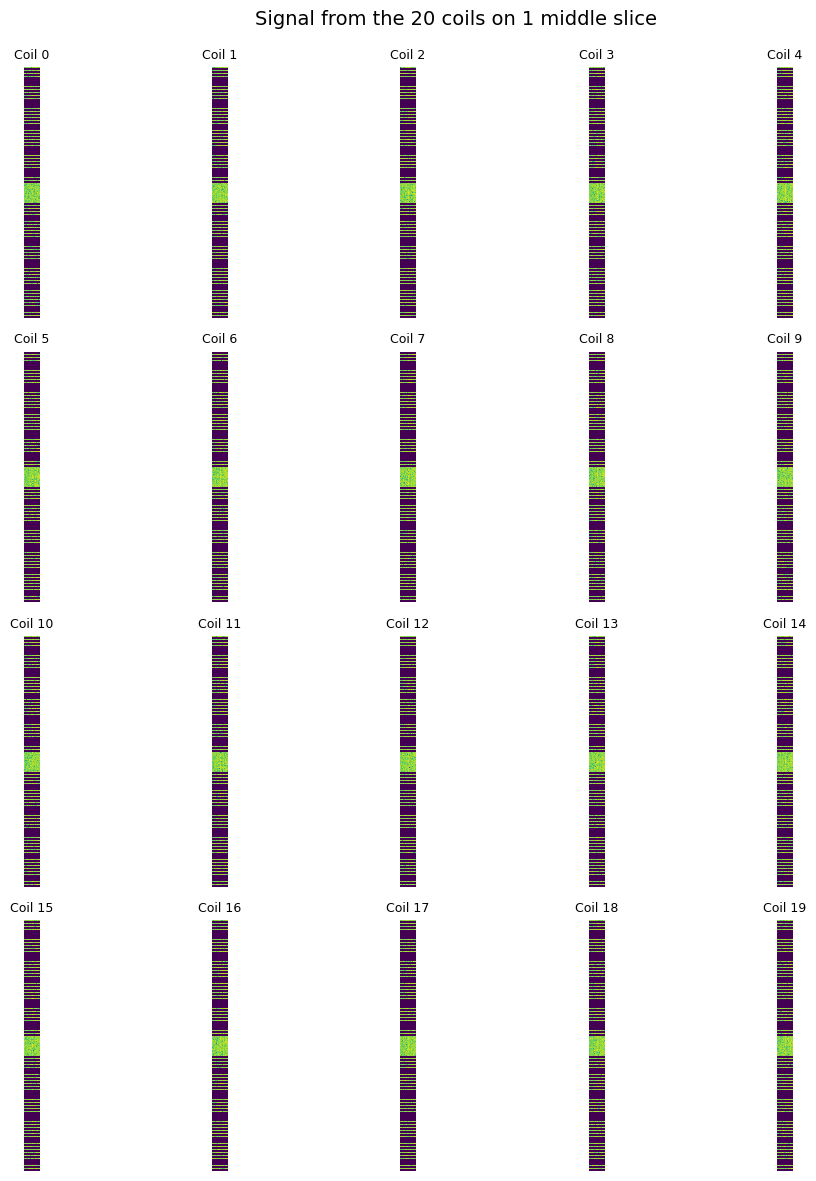

In [34]:
def show_coils_grid(data, coil_indices=None, cmap='viridis', nrows=4, ncols=5, fig_size=(12,9)):
    if coil_indices is None:
        coil_indices = list(range(data.shape[0]))
    fig, axes = plt.subplots(nrows, ncols, figsize=fig_size)
    axes = axes.flatten()
    # consistent color scaling across all coils
    vals = np.array([data[i] for i in coil_indices])
    vmin = vals.min()
    vmax = vals.max()
    im = None
    for ax, idx in zip(axes, coil_indices):
        im = ax.imshow(data[idx], cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_title(f'Coil {idx}', fontsize=9)
        ax.axis('off')
    # turn off any unused axes
    for ax in axes[len(coil_indices):]:
        ax.axis('off')
    fig.tight_layout(rect=[0,0,0.92,0.96])
    fig.suptitle('Signal from the 20 coils on 1 middle slice', fontsize=14)


# display log-magnitude of k-space (small constant to avoid log(0))
data_to_show = np.log(np.abs(kspace) + 1e-9)
show_coils_grid(data_to_show, coil_indices=[i for i in range(0, 20)], cmap='viridis', nrows=4, ncols=5, fig_size=(12,12))